In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [11]:
channels=  [ 
    # "cr_Zmumu_noLJ",
    "cr_Zmumu_noLJ_noVeto",
           ]

samples_separate = [
    # "TTJets",
               "DYJetsToLL",
               # "QCD",
               # "Diboson",
              # "data"
              ]
samples = ["bgs", "data",
           # "TTJets",
               # "DYJetsToLL",
               # "QCD",
               # "Diboson",
          ]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}/2026_27_10"
        try:
            sum_h= utilities.sum_hist(list1, folder_name)
            sum_hist[channel_name][s] = sum_h
        except:
            continue



In [10]:
sum_hist['cr_Zmumu_noLJ_noVeto']['data'].keys()

dict_keys(['muon_eta_phi_pixelHits', 'muon_PixelHits_vs_genAs_toMu_Lxy'])

('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')
('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')


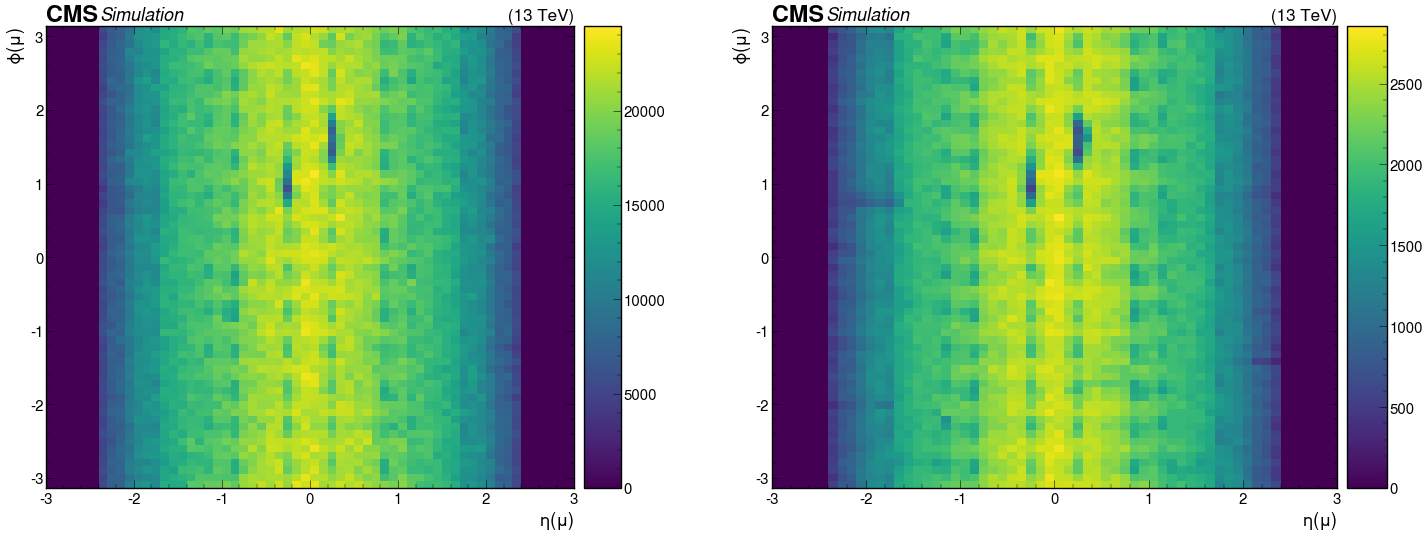

In [18]:
n = len(samples)
for channel_name in channels:
    fig, axs = plt.subplots(1, n, figsize=(15*n, 12))
    for i, s in enumerate(samples):
        histogram =  sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][channel_name, :, :, :]
        print(histogram.axes.name)
        hist_2d = histogram.project("muon_eta", "muon_phi")
        utilities.plot(hist_2d, ax=axs[i])
        
        

